# Where should Picnic open its next hub in Germany?
*A district-level white-space analysis using open public data · Data Analyst internship portfolio project*

---

## Executive summary

**Recommendation: open the next hubs in Augsburg, then in the Karlsruhe region and Aachen.** All three are dense, sizeable markets with no public evidence of Picnic presence, and all three sit close enough to Picnic's existing network to be supplied without building a new fulfilment centre first.

| | Augsburg | Karlsruhe region | Aachen |
|---|---|---|---|
| White-space rank | **#1** | #3 / #4 (district / city) | #2 |
| Top-10 in weight scenarios | **100%** | 90% / 75% | 90% |
| Rank if income is added to the score | #1 | #6 / #3 | #2 |
| Households in ≤30 km white-space cluster | ~350k | **~612k** | ~281k |
| Hub-equivalents (upper bound, 100k hh/hub) | 3.5 | **6.1** | 2.8 |
| Distance to the Picnic network | 53 km (Munich) | 46–54 km (Mannheim); 60–70 km to the Viernheim FC | 40 km (Rhine-Ruhr) |

**Why I trust the ranking:**
- The drivers explain Picnic's *past* choices. A density/size/growth index separates districts with and without Picnic with an **AUC of 0.87**. Picnic is present in **72%** of top-decile districts but only **4%** of the bottom half.
- **Income was tested and deliberately left out.** Holding density and size constant, higher wages are linked to a *lower* chance of Picnic presence (p = 0.02), which fits Picnic's mass-market positioning. Even with income added to the score, 9 of the top 10 stay the same.
- The top three stay in the top 10 in **≥ 90%** of 2,000 random weight scenarios (Karlsruhe city: 75%).
- The shortlist was checked manually against press and job-ad evidence (Section 9).

**Scope:** 400 German districts, open data only (Destatis population via RKI, district median wages, Eurostat boundaries). Picnic's footprint was rebuilt from public evidence and a list of Picnic site addresses: **56 districts, about 31% of Germany's population**.

**Reading time:** ~5 minutes. Every number in the summary is computed below. The notebook runs end-to-end in under 30 seconds from the files in `data/raw/`.

## 1. The business question

Picnic delivers groceries with the **"milkman" model**. Orders are picked in a regional **fulfilment centre (FC)**, trucked to a local **hub**, and delivered from there by small electric vans on fixed daily routes. This model has two consequences for where a new hub should go:

1. **Density drives unit economics.** More households per km² means more drops per route hour. The press reports 6–8 customers per hour.
2. **A hub is only viable within trucking range of an FC.** New hubs near the existing network can be supplied right away; a new region first needs a new FC, which is a much larger investment.

Picnic is also a mass-market, low-price proposition, so the size of the addressable market (households) matters more than affluence.

**Question:** *Which German districts outside Picnic's current catchments are the most attractive locations for the next hub?*

**Approach** (deliberately simple and transparent, as a first screening an analyst would bring to an expansion meeting):

| Step | What | Why |
|---|---|---|
| 1 | Build a table of all **400 German districts** (*Kreise*) with population, area, density, growth and median wage | The district is the smallest unit with complete open data |
| 2 | Map Picnic's **current footprint** from public evidence (press releases, job ads) | Defines what is already served and where supply exists |
| 3 | **Sanity-check** the drivers against the districts Picnic has already chosen | A model should explain past decisions before it predicts future ones |
| 4 | Score the **white space** on density, market size, network proximity and growth | A transparent weighted index anyone can challenge |
| 5 | Test **robustness** to the weights (Monte Carlo) and **size** the top picks | A recommendation that changes with every weight tweak is no recommendation |

## 2. Setup and assumptions

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

DATA = Path("../data/raw")
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

# ---- Chart styling (one consistent, colour-blind-safe palette) ---------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
NEUTRAL_LIGHT, NEUTRAL_MID = "#eeede9", "#b9b8b2"
SEQ_BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False,
})

In [2]:
# ---- Business assumptions: all in one place, all easy to challenge ----------------
HOUSEHOLD_SIZE   = 2.0      # persons per household (German average is about 2)
HUB_CAPACITY_HH  = 100_000  # households one hub can serve (press examples: 80k-125k)
CATCHMENT_KM     = 30       # districts closer than this to a known Picnic site = "infill zone"
SUPPLY_FULL_KM   = 100      # within this distance of the network, supply from an existing FC is easy
SUPPLY_ZERO_KM   = 250      # beyond this, a new region (and a new FC) would be needed

WEIGHTS = {"density": 0.35, "size": 0.30, "network": 0.25, "growth": 0.10}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

## 3. Data

All sources are open (CC BY 4.0 or equivalent) and saved as small files in `data/raw/`, so the notebook runs offline.

| File | Content | Source |
|---|---|---|
| `rki_population_31122022_by_district.csv` | Population per district, reference date 31.12.2022 (Destatis population statistics) | Robert Koch-Institut, open GitHub data repository *COVID-19_7-Tage-Inzidenz_in_Deutschland* |
| `destatis_districts_2018.csv` | Area (km²), population 31.12.2018, NUTS-3 code per district | Destatis *Gemeindeverzeichnis*, via the open `landkreise-deutschland` package |
| `lohntastik_median_salary_by_district.csv` | Median gross monthly wage of full-time employees per district, plus number of full-time employees (social-security data, 2022) | LohnTastik, extracted from the data behind its interactive map ([article](https://lohntastik.de/blog/median_de/median-salary-in-germany)) |
| `eurostat_nuts3_2021_DE_10M.geojson` | District boundaries (NUTS-3, 2021, 1:10M) | Eurostat GISCO via `eurostat/Nuts2json` |
| `picnic_presence_public_evidence.csv` | Districts with **public evidence** of Picnic presence (hub, FC or delivery area), one source URL per row | Hand-curated from press releases, job ads and an address list of Picnic sites from Google Maps listings (November 2026) |

> **Caveat on the footprint:** Picnic does not publish a coverage map, so the footprint is a *lower bound* built from public evidence. The analysis allows for this: it only recommends districts **at least 30 km** from any known site, and it checks the final shortlist manually (Section 9).

In [3]:
districts = pd.read_csv(DATA / "destatis_districts_2018.csv", sep=";", dtype={"AGS": str})
pop_raw   = pd.read_csv(DATA / "rki_population_31122022_by_district.csv", dtype={"district_id": str})
geo       = gpd.read_file(DATA / "eurostat_nuts3_2021_DE_10M.geojson").rename(columns={"id": "NUTS3"})
presence  = pd.read_csv(DATA / "picnic_presence_public_evidence.csv", dtype={"district_id": str})
wages_raw = pd.read_csv(DATA / "lohntastik_median_salary_by_district.csv", sep=";", dtype={"AGS": str})

print(f"Destatis districts: {len(districts)} | RKI population rows: {len(pop_raw)} | "
      f"NUTS-3 shapes: {len(geo)} | Picnic evidence rows: {len(presence)} | wage rows: {len(wages_raw)}")

Destatis districts: 401 | RKI population rows: 411 | NUTS-3 shapes: 401 | Picnic evidence rows: 56 | wage rows: 419


### 3.1 Cleaning: two known differences between the sources
* **Berlin:** RKI reports Berlin's 12 boroughs separately (`11001`–`11012`); every other source treats Berlin as one district (`11000`). Aggregate.
* **Eisenach:** merged into the Wartburgkreis in 2021 (`16056` → `16063`). The 2018 table and the 2021 shapes still list it separately. Merge it.
* **Wage file:** also contains state, East/West and national totals, so keep only 5-digit district codes. The wage file was copied from a web page, so I check that the district employee counts add up **exactly** to each published state total.

In [4]:
# Population 2022 per district (Berlin boroughs -> Berlin)
pop_raw["AGS"] = np.where(pop_raw.district_id.str.startswith("11"), "11000", pop_raw.district_id)
pop22 = pop_raw.groupby("AGS")["population_2022"].sum()

# Shapes + Destatis attributes, then merge Eisenach into Wartburgkreis
gdf = geo.merge(districts, on="NUTS3", how="inner", validate="1:1")
gdf["AGS"] = gdf["AGS"].replace({"16056": "16063"})
gdf = (gdf.dissolve(by="AGS", aggfunc={"name": "first", "type": "last", "area_km2": "sum", "population": "sum"})
          .reset_index()
          .rename(columns={"population": "population_2018"}))
gdf.loc[gdf.AGS == "16063", ["name", "type"]] = ["Wartburgkreis", "Landkreis"]
gdf["population_2022"] = gdf["AGS"].map(pop22)

# Median wage: keep district rows only; verify the copied data against the state totals in the same file
wages = wages_raw[wages_raw.AGS.str.len() == 5].set_index("AGS")
states_tot = wages_raw[wages_raw.AGS.str.len() == 2].set_index("AGS")["fulltime_employees"]
by_state = wages.drop(index="11000").groupby(lambda a: a[:2])["fulltime_employees"].sum()
by_state["11"] = wages.loc["11000", "fulltime_employees"]
assert (by_state.sort_index() == states_tot.sort_index()).all(), "district employees must add up to state totals"
gdf["median_wage"] = gdf["AGS"].map(wages["median_gross_monthly_eur"])

# Readable labels: "Augsburg (city)" vs "Augsburg (district)" when the name is ambiguous
STATES = {"01": "Schleswig-Holstein", "02": "Hamburg", "03": "Niedersachsen", "04": "Bremen",
          "05": "Nordrhein-Westfalen", "06": "Hessen", "07": "Rheinland-Pfalz", "08": "Baden-Württemberg",
          "09": "Bayern", "10": "Saarland", "11": "Berlin", "12": "Brandenburg",
          "13": "Mecklenburg-Vorpommern", "14": "Sachsen", "15": "Sachsen-Anhalt", "16": "Thüringen"}
gdf["state"] = gdf.AGS.str[:2].map(STATES)
gdf["is_city"] = gdf["type"].isin(["Kreisfreie Stadt", "Stadtkreis"])
gdf["district"] = gdf["name"].str.split(",").str[0].str.strip()
dup = gdf["district"].duplicated(keep=False)
gdf.loc[dup, "district"] += np.where(gdf.loc[dup, "is_city"], " (city)", " (district)")

# ---- Data-quality checks ----------------------------------------------------------
assert len(gdf) == 400, "Germany has 400 districts"
assert gdf["population_2022"].notna().all(), "every district has a population"
assert gdf["median_wage"].notna().all(), "every district has a median wage"
assert gdf["population_2022"].sum() == pop_raw["population_2022"].sum(), "no population lost in the merge"
assert presence["district_id"].isin(gdf.AGS).all(), "every Picnic evidence row maps to a district"
assert not presence["district_id"].duplicated().any()
print(f"OK: 400 districts, {gdf.population_2022.sum():,} inhabitants, "
      f"{gdf.area_km2.sum():,.0f} km², {presence.district_id.nunique()} districts with Picnic evidence; "
      f"wage file reconciles with all 16 state totals")

OK: 400 districts, 84,358,845 inhabitants, 357,575 km², 56 districts with Picnic evidence; wage file reconciles with all 16 state totals


### 3.2 Features

In [5]:
gdf["households"]   = gdf["population_2022"] / HOUSEHOLD_SIZE
gdf["density"]      = gdf["population_2022"] / gdf["area_km2"]          # inhabitants per km²
gdf["growth_18_22"] = gdf["population_2022"] / gdf["population_2018"] - 1   # same statistical basis (Census 2011)

# Picnic presence + distance from every district centroid to the nearest known Picnic site
site_info = presence.set_index("district_id")
gdf["picnic_present"] = gdf["AGS"].isin(site_info.index)

cent = gdf.to_crs(3035).geometry.centroid                  # metric CRS (ETRS89-LAEA) for distances in km
xy = np.c_[cent.x, cent.y]
dist = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)) / 1000   # 400 x 400 matrix, km

site_idx = np.where(gdf["picnic_present"])[0]
gdf["dist_to_picnic_km"] = dist[:, site_idx].min(1)
gdf["nearest_picnic_site"] = gdf["district"].values[site_idx[dist[:, site_idx].argmin(1)]]

fc_types = {"fulfilment centre", "warehouse"}
fc_idx = np.where(gdf["AGS"].map(site_info["site_type"]).isin(fc_types))[0]
gdf["dist_to_fc_km"] = dist[:, fc_idx].min(1)
gdf["nearest_fc"] = gdf["district"].values[fc_idx[dist[:, fc_idx].argmin(1)]]

gdf["zone"] = np.select(
    [gdf.picnic_present, gdf.dist_to_picnic_km < CATCHMENT_KM],
    ["Picnic present", f"Infill zone (<{CATCHMENT_KM} km)"], "White space")

gdf.groupby("zone").agg(districts=("AGS", "size"),
                        population_m=("population_2022", lambda s: s.sum() / 1e6),
                        median_density=("density", "median"),
                        median_wage_eur=("median_wage", "median")).round(1)

,districts,population_m,median_density,median_wage_eur
zone,,,,
Infill zone (<30 km),82,18.20,293.60,"3,490.30"
Picnic present,56,25.90,"1,426.00","3,688.90"
White space,262,40.30,147.00,"3,395.50"


## 4. Picnic's footprint today

Picnic grew out of the Rhine-Ruhr area (first German city: Neuss, 2018) and has since added clusters around Hamburg, Berlin, Hannover/Bremen, Rhine-Main/Rhine-Neckar, Stuttgart, Munich/Franconia and, most recently, the Halle–Leipzig–Dresden–Magdeburg region. The address list adds sites in Langenfeld (Kreis Mettmann), Offenbach am Main and Neumünster. The light-blue *infill zone* marks districts so close to an existing site that a new hub there would be **densification**, not a new market.

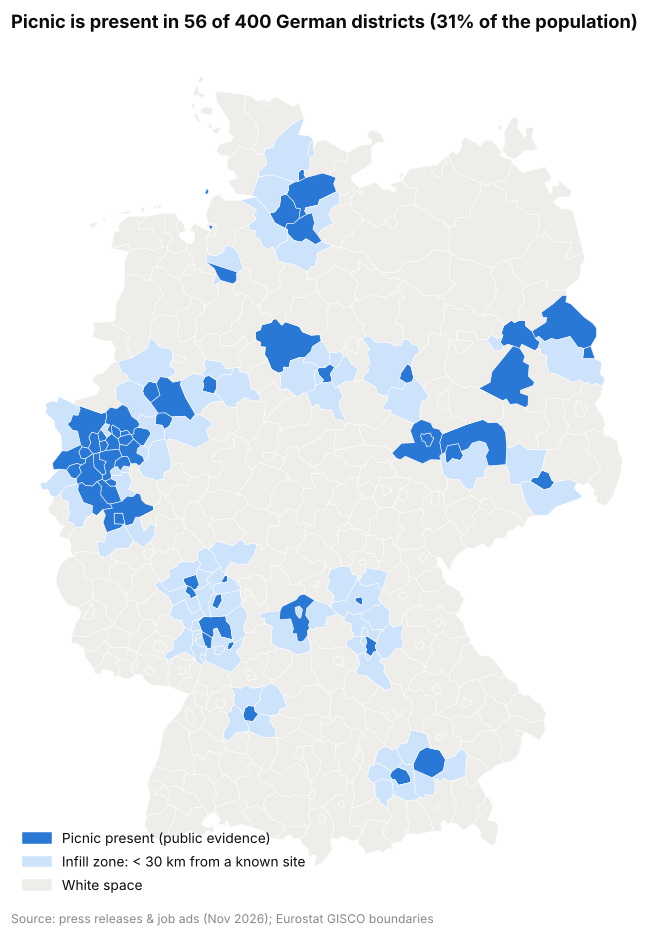

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 8.6))
colors = gdf["zone"].map({"Picnic present": BLUE,
                          f"Infill zone (<{CATCHMENT_KM} km)": SEQ_BLUES[0],
                          "White space": NEUTRAL_LIGHT})
gdf.plot(ax=ax, color=colors, edgecolor="white", linewidth=0.35)
ax.set_axis_off()
ax.set_title(f"Picnic is present in {gdf.picnic_present.sum()} of 400 German districts "
             f"({gdf.loc[gdf.picnic_present, 'population_2022'].sum() / gdf.population_2022.sum():.0%} of the population)")
ax.legend(handles=[Patch(color=BLUE, label="Picnic present (public evidence)"),
                   Patch(color=SEQ_BLUES[0], label=f"Infill zone: < {CATCHMENT_KM} km from a known site"),
                   Patch(color=NEUTRAL_LIGHT, label="White space")],
          loc="lower left", fontsize=9)
ax.annotate("Source: press releases & job ads (Nov 2026); Eurostat GISCO boundaries",
            (0, -0.02), xycoords="axes fraction", fontsize=8, color=MUTED)
plt.tight_layout(); plt.savefig(OUT / "01_footprint_map.png", bbox_inches="tight"); plt.show()

## 5. Sanity check: do density and market size explain where Picnic already is?

Before scoring the white space, I check the drivers against Picnic's actual decisions. I compute a **market attractiveness index** from density, market size and growth only. Distance is excluded, because it is defined by the footprint itself. If the index is meaningful, districts where Picnic already operates should score clearly higher.

In [7]:
pct = lambda s: s.rank(pct=True)             # percentile rank: robust to outliers such as Munich or Berlin
gdf["s_density"] = pct(np.log(gdf["density"]))
gdf["s_size"]    = pct(np.log(gdf["households"]))
gdf["s_growth"]  = pct(gdf["growth_18_22"])

w_mkt = {k: WEIGHTS[k] for k in ("density", "size", "growth")}
gdf["market_index"] = sum(w * gdf[f"s_{k}"] for k, w in w_mkt.items()) / sum(w_mkt.values())

auc = roc_auc_score(gdf["picnic_present"], gdf["market_index"])
gdf["market_decile"] = pd.qcut(gdf["market_index"], 10, labels=range(1, 11)).astype(int)
by_decile = gdf.groupby("market_decile")["picnic_present"].mean()
print(f"AUC of the market index vs. actual Picnic presence: {auc:.2f}  (0.5 = random, 1.0 = perfect)")
print(f"Picnic present in {by_decile.loc[10]:.0%} of top-decile districts vs {by_decile.loc[1:5].mean():.0%} in the bottom half")

AUC of the market index vs. actual Picnic presence: 0.87  (0.5 = random, 1.0 = perfect)
Picnic present in 72% of top-decile districts vs 4% in the bottom half


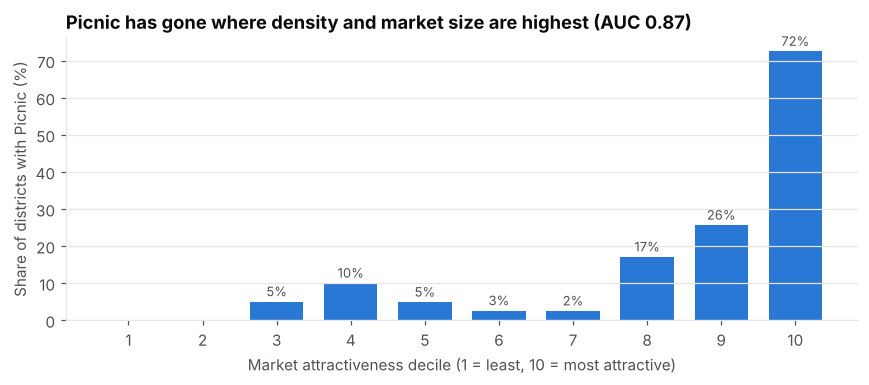

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(by_decile.index, by_decile.values * 100, color=BLUE, width=0.72)
for b, v in zip(bars, by_decile.values):
    if v > 0:
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(range(1, 11)); ax.set_xlabel("Market attractiveness decile (1 = least, 10 = most attractive)")
ax.set_ylabel("Share of districts with Picnic (%)"); ax.grid(axis="x", visible=False)
ax.set_title(f"Picnic has gone where density and market size are highest (AUC {auc:.2f})")
plt.tight_layout(); plt.savefig(OUT / "02_validation_deciles.png", bbox_inches="tight"); plt.show()

**Takeaway:** the simple index separates Picnic districts from the rest well. Picnic's past choices follow exactly the density-and-scale logic of the milkman model, which supports using the same drivers to rank the remaining white space.

### 5.1 Should income be in the score?
Income is the obvious extra variable for a retailer. But Picnic positions itself as a **low-price, mass-market** supermarket, so I test whether income *adds* anything to density and size before using it. Two checks:
1. **Logistic regression** of Picnic presence on all four percentile features: what is the effect of income *holding density and size constant*?
2. **AUC** of the market index with and without a 10% income weight.

In [9]:
gdf["s_income"] = pct(gdf["median_wage"])
X = gdf[["s_density", "s_size", "s_growth", "s_income"]]
y = gdf["picnic_present"].astype(int)

full = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
restricted = sm.Logit(y, sm.add_constant(X.drop(columns="s_income"))).fit(disp=0)
lr_p = 1 - stats.chi2.cdf(2 * (full.llf - restricted.llf), df=1)

w_inc = {"density": 0.30, "size": 0.25, "growth": 0.10, "income": 0.10}
auc_inc = roc_auc_score(y, sum(w * gdf[f"s_{k}"] for k, w in w_inc.items()))

print(f"Correlation income vs density (percentiles): {gdf.s_income.corr(gdf.s_density):.2f}")
print(f"AUC market index without income: {auc:.3f} | with 10% income: {auc_inc:.3f}")
print(f"Likelihood-ratio test for adding income: p = {lr_p:.3f}\n")
full.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].rename(index=lambda i: i.replace("s_", "")).round(3)

Correlation income vs density (percentiles): 0.63
AUC market index without income: 0.866 | with 10% income: 0.851
Likelihood-ratio test for adding income: p = 0.018



,Coef.,Std.Err.,P>|z|
const,-7.31,0.97,0.00
density,6.83,1.17,0.00
size,3.63,0.73,0.00
growth,-0.09,0.71,0.90
income,-2.04,0.88,0.02


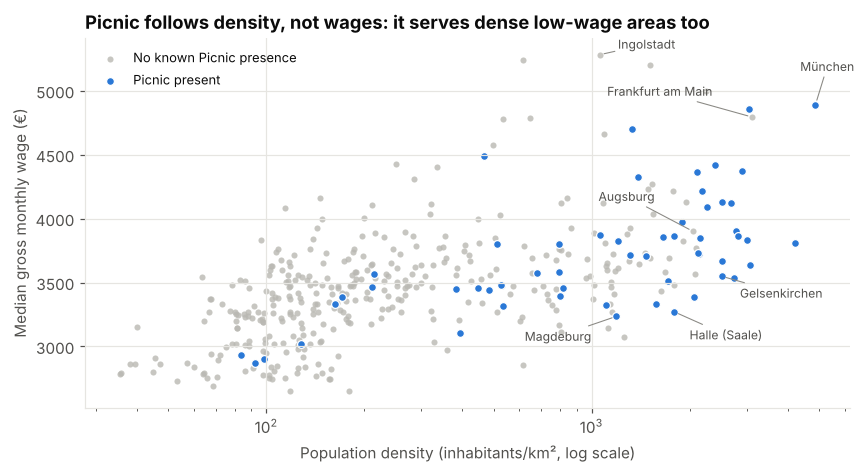

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.4))
no = gdf[~gdf.picnic_present]; yes = gdf[gdf.picnic_present]
ax.scatter(no.density, no.median_wage, s=16, color=NEUTRAL_MID, alpha=0.8, label="No known Picnic presence", linewidths=0)
ax.scatter(yes.density, yes.median_wage, s=26, color=BLUE, label="Picnic present", edgecolor="white", linewidth=0.8)
labels = {"Halle (Saale)": (10, -18), "Magdeburg": (-60, -16), "Gelsenkirchen": (12, -14),
          "München": (-10, 22), "Frankfurt am Main": (-95, 14), "Ingolstadt": (12, 4),
          "Augsburg (city)": (-62, 20)}
for name, (dx, dy) in labels.items():
    r = gdf[gdf.district.str.startswith(name)].iloc[0]
    ax.annotate(name.replace(" (city)", ""), (r.density, r.median_wage), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.7, shrinkA=0, shrinkB=3))
ax.set_xscale("log"); ax.set_xlabel("Population density (inhabitants/km², log scale)")
ax.set_ylabel("Median gross monthly wage (€)")
ax.set_title("Picnic follows density, not wages: it serves dense low-wage areas too")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.savefig(OUT / "02b_density_vs_wage.png", bbox_inches="tight"); plt.show()

**Takeaway:** income is strongly correlated with density, and **once density and size are controlled for, its effect on Picnic's presence is negative**. Picnic is, if anything, *more* likely to be in lower-wage districts (Ruhr cities, Halle, Magdeburg). Adding income does not improve the index either. So income is **left out of the base score** (consistent with Picnic's mass-market proposition) and tested as an alternative scenario in Section 7.

*Caveat:* the wage data appears to count employees at their **place of work**: Ingolstadt, Wolfsburg and Ludwigshafen top the list because of Audi, VW and BASF. Districts with large employers therefore look richer than their residents are, which is another reason not to give wages much weight.

## 6. Scoring the white space

Each eligible district (no known Picnic presence and **≥ 30 km** from any known site) gets a 0–1 score:

| Component | Weight | Measure | Business logic |
|---|---|---|---|
| Density | 35% | percentile of log(inhabitants/km²) | Drops per route hour → cost per order |
| Market size | 30% | percentile of log(households) | Hub utilisation and revenue potential |
| Network proximity | 25% | 1 up to 100 km from the network, linear to 0 at 250 km | Can an existing FC supply it, or is a new FC needed? |
| Growth | 10% | percentile of population growth 2018→22 | Future demand; young households |

In [11]:
d = gdf["dist_to_picnic_km"]
gdf["s_network"] = np.clip(1 - (d - SUPPLY_FULL_KM) / (SUPPLY_ZERO_KM - SUPPLY_FULL_KM), 0, 1)

def score(frame, w):
    return sum(w[k] * frame[f"s_{k}"] for k in w)

gdf["score"] = score(gdf, WEIGHTS)
ws = gdf[gdf["zone"] == "White space"].sort_values("score", ascending=False).copy()
ws["rank"] = range(1, len(ws) + 1)

top10 = ws.head(10)
(top10[["rank", "district", "state", "population_2022", "density", "growth_18_22", "median_wage",
        "dist_to_picnic_km", "nearest_picnic_site", "score"]]
     .rename(columns={"population_2022": "population", "density": "inh/km²", "growth_18_22": "growth 18-22", "median_wage": "median wage €",
                      "dist_to_picnic_km": "km to Picnic", "nearest_picnic_site": "nearest Picnic site"})
     .style.format({"population": "{:,.0f}", "inh/km²": "{:,.0f}", "growth 18-22": "{:+.1%}",
                    "median wage €": "{:,.0f}", "km to Picnic": "{:.0f}", "score": "{:.3f}"})
     .hide(axis="index").bar(subset=["score"], color="#cde2fb", vmin=0.6, vmax=1))

rank,district,state,population,inh/km²,growth 18-22,median wage €,km to Picnic,nearest Picnic site,score
1,Augsburg (city),Bayern,"301,033","2,050",+2.0%,"3,900",53,München (city),0.895
2,Städteregion Aachen,Nordrhein-Westfalen,"562,559",796,+1.3%,"3,762",40,Rhein-Erft-Kreis,0.849
3,Karlsruhe (district),Baden-Württemberg,"454,613",419,+2.3%,"3,717",46,Mannheim,0.837
4,Karlsruhe (city),Baden-Württemberg,"308,707","1,780",-1.4%,"4,215",54,Mannheim,0.836
5,Main-Kinzig-Kreis,Hessen,"430,838",308,+2.8%,"3,547",39,Offenbach am Main,0.824
6,Heilbronn (district),Baden-Württemberg,"353,283",321,+3.0%,"4,118",45,Stuttgart,0.822
7,Oldenburg (Oldenburg),Niedersachsen,"172,830","1,676",+2.7%,"3,581",37,Bremen,0.817
8,Regensburg (city),Bayern,"157,443","1,947",+3.2%,"4,127",80,Erding,0.816
9,Kassel (city),Hessen,"204,202","1,912",+1.3%,"3,826",101,Bielefeld,0.812
10,Gießen,Hessen,"278,664",326,+3.6%,"3,641",53,Offenbach am Main,0.808


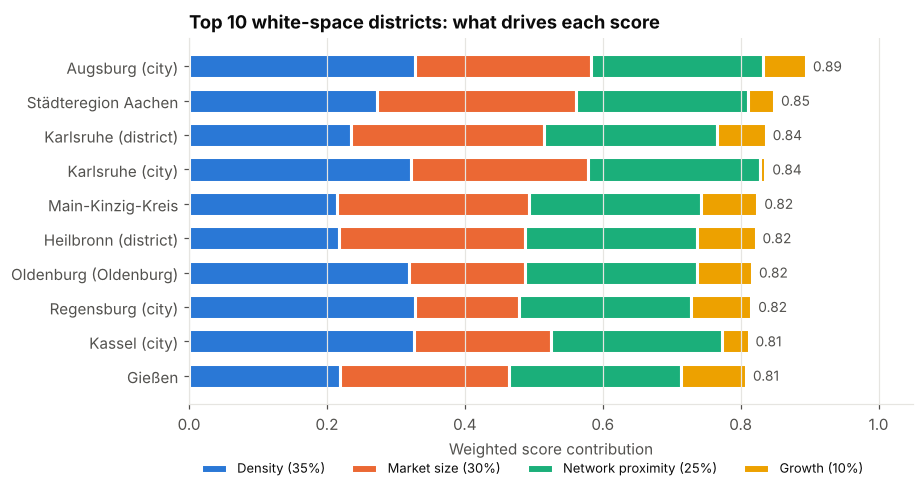

In [12]:
comp = pd.DataFrame({k: WEIGHTS[k] * top10[f"s_{k}"].values for k in WEIGHTS}, index=top10["district"].values)[::-1]
labels = {"density": "Density (35%)", "size": "Market size (30%)", "network": "Network proximity (25%)", "growth": "Growth (10%)"}
fig, ax = plt.subplots(figsize=(8.5, 4.6))
left = np.zeros(len(comp))
for k, c in zip(WEIGHTS, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.barh(comp.index, comp[k], left=left, color=c, height=0.7, edgecolor="white", linewidth=2, label=labels[k])
    left += comp[k].values
for y, tot in enumerate(left):
    ax.text(tot + 0.01, y, f"{tot:.2f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False); ax.set_xlabel("Weighted score contribution")
ax.set_title("Top 10 white-space districts: what drives each score")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12), fontsize=8.5)
plt.tight_layout(); plt.savefig(OUT / "03_top10_score_drivers.png", bbox_inches="tight"); plt.show()

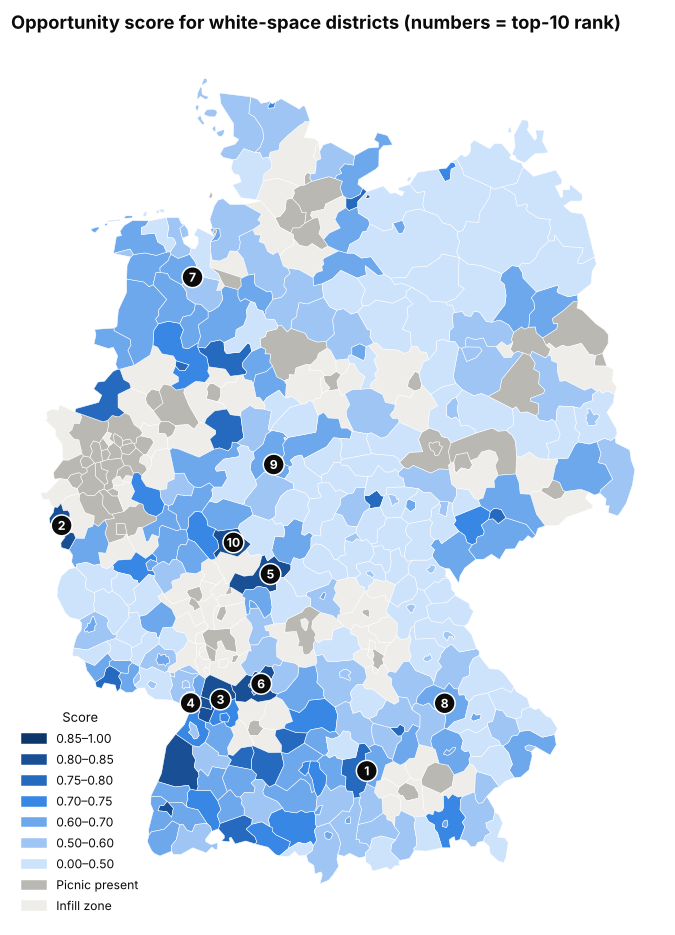

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 8.6))
gdf[gdf.zone != "White space"].plot(ax=ax, color=gdf.loc[gdf.zone != "White space", "picnic_present"]
                                    .map({True: NEUTRAL_MID, False: NEUTRAL_LIGHT}), edgecolor="white", linewidth=0.35)
bins = [0, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 1.0]
ws["score_bin"] = pd.cut(ws["score"], bins, labels=False, include_lowest=True)
ws.plot(ax=ax, color=ws["score_bin"].map(dict(enumerate(SEQ_BLUES))), edgecolor="white", linewidth=0.35)

placed = []
for _, r in top10.iterrows():
    p = r.geometry.representative_point()
    # nudge a label sideways if it would sit on top of a previous one (e.g. Karlsruhe city inside Karlsruhe district)
    dx = -9 if any(abs(p.x - q.x) < 0.35 and abs(p.y - q.y) < 0.25 for q in placed) else 0
    placed.append(p)
    ax.annotate(str(r["rank"]), (p.x, p.y), xytext=(dx, 0), textcoords="offset points",
                ha="center", va="center", fontsize=8, fontweight="bold", color="white",
                bbox=dict(boxstyle="circle,pad=0.25", fc=INK, ec="white", lw=1))
ax.set_axis_off()
ax.set_title("Opportunity score for white-space districts (numbers = top-10 rank)")
handles = [Patch(color=SEQ_BLUES[i], label=f"{bins[i]:.2f}–{bins[i+1]:.2f}") for i in range(len(SEQ_BLUES))][::-1]
handles += [Patch(color=NEUTRAL_MID, label="Picnic present"), Patch(color=NEUTRAL_LIGHT, label="Infill zone")]
ax.legend(handles=handles, title="Score", loc="lower left", fontsize=8, title_fontsize=8.5)
plt.tight_layout(); plt.savefig(OUT / "04_opportunity_map.png", bbox_inches="tight"); plt.show()

## 7. Robustness: does the ranking survive different weights?

The weights are a judgement call, so I re-score the white space **2,000 times** with random weights drawn around the base case (Dirichlet distribution), then count how often each district lands in the top 10.

In [14]:
rng = np.random.default_rng(42)
keys = list(WEIGHTS)
draws = rng.dirichlet(np.array([WEIGHTS[k] for k in keys]) * 20, size=2000)   # mean = base weights
S = ws[[f"s_{k}" for k in keys]].values @ draws.T                               # districts x simulations
ranks = (-S).argsort(0).argsort(0) + 1

ws["top10_share"] = (ranks <= 10).mean(1)
ws["rank_p10"], ws["rank_p90"] = np.percentile(ranks, 10, axis=1), np.percentile(ranks, 90, axis=1)
robust = ws.sort_values("top10_share", ascending=False).head(15)
print(f"Weight ranges explored (10th-90th percentile): " +
      ", ".join(f"{k} {np.percentile(draws[:, i], 10):.0%}-{np.percentile(draws[:, i], 90):.0%}" for i, k in enumerate(keys)))
robust[["district", "rank", "top10_share", "rank_p10", "rank_p90"]].rename(
    columns={"rank": "base rank", "top10_share": "% of runs in top 10", "rank_p10": "rank P10", "rank_p90": "rank P90"}
).style.format({"% of runs in top 10": "{:.0%}", "rank P10": "{:.0f}", "rank P90": "{:.0f}"}).hide(axis="index")

Weight ranges explored (10th-90th percentile): density 22%-49%, size 17%-43%, network 14%-38%, growth 3%-19%


district,base rank,% of runs in top 10,rank P10,rank P90
Augsburg (city),1,100%,1,2
Städteregion Aachen,2,90%,2,10
Karlsruhe (district),3,90%,2,10
Main-Kinzig-Kreis,5,77%,3,14
Karlsruhe (city),4,75%,2,22
Heilbronn (district),6,74%,4,15
Oldenburg (Oldenburg),7,64%,3,24
Regensburg (city),8,60%,2,27
Kassel (city),9,56%,4,24
Freiburg im Breisgau,11,50%,4,26


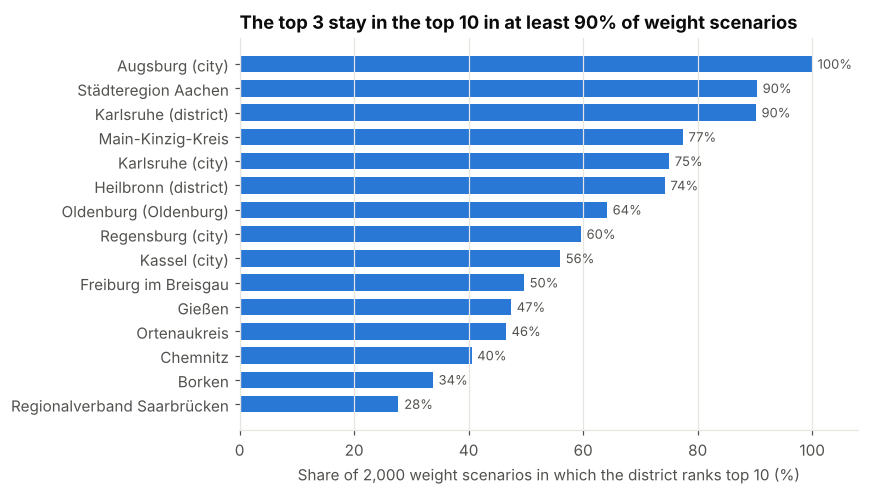

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.6))
r = robust[::-1]
ax.barh(r["district"], r["top10_share"] * 100, color=BLUE, height=0.68)
for y, v in enumerate(r["top10_share"]):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, 108); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of 2,000 weight scenarios in which the district ranks top 10 (%)")
top3_min = ws.head(3)["top10_share"].min()
ax.set_title(f"The top 3 stay in the top 10 in at least {top3_min:.0%} of weight scenarios")
plt.tight_layout(); plt.savefig(OUT / "05_robustness.png", bbox_inches="tight"); plt.show()

**Income scenario:** what if management insisted on purchasing power? I re-score with income at 10% (density 30%, size 25%, network 25%, growth 10%, income 10%) and compare the top 10.

In [16]:
W_INCOME = {"density": 0.30, "size": 0.25, "network": 0.25, "growth": 0.10, "income": 0.10}
ws["score_income"] = score(ws, W_INCOME)
ws["rank_income"] = ws["score_income"].rank(ascending=False, method="first").astype(int)
cmp = ws.sort_values("rank").head(12)[["district", "median_wage", "rank", "rank_income"]]
cmp["change"] = cmp["rank"] - cmp["rank_income"]
print("Top-10 overlap between base and income scenario:",
      len(set(ws.nsmallest(10, "rank").AGS) & set(ws.nsmallest(10, "rank_income").AGS)), "of 10")
cmp.rename(columns={"median_wage": "median wage €", "rank": "base rank", "rank_income": "rank with income"}).style.format(
    {"median wage €": "{:,.0f}", "change": "{:+d}"}).hide(axis="index")

Top-10 overlap between base and income scenario: 9 of 10


district,median wage €,base rank,rank with income,change
Augsburg (city),"3,900",1,1,+0
Städteregion Aachen,"3,762",2,2,+0
Karlsruhe (district),"3,717",3,6,-3
Karlsruhe (city),"4,215",4,3,+1
Main-Kinzig-Kreis,"3,547",5,10,-5
Heilbronn (district),"4,118",6,4,+2
Oldenburg (Oldenburg),"3,581",7,9,-2
Regensburg (city),"4,127",8,5,+3
Kassel (city),"3,826",9,8,+1
Gießen,"3,641",10,11,-1


## 8. Sizing the shortlist

A hub serves roughly 80–125k households (examples from Picnic launches: Herten 80k, Leverkusen 83k, Münster 105k, Essen 125k). For each shortlisted district I add up the households of the district **plus neighbouring white-space districts within 30 km**, the area one or two hubs could realistically grow into. Dividing by 100k gives an *upper bound* of hub-equivalents. Not every household is reachable on dense routes, so treat it as an order of magnitude.

In [17]:
pos = {a: i for i, a in enumerate(gdf.AGS)}
ws_idx = np.array([pos[a] for a in ws.AGS])

def cluster(a):
    i = pos[a]
    members = ws_idx[dist[i, ws_idx] < CATCHMENT_KM]
    return gdf.iloc[members]

rows = []
for _, r in ws.head(10).iterrows():
    c = cluster(r.AGS)
    rows.append({"rank": r["rank"], "district": r["district"],
                 "households": r["households"],
                 "cluster households (≤30 km)": c["households"].sum(),
                 "hub-equivalents (upper bound)": c["households"].sum() / HUB_CAPACITY_HH,
                 "cluster members": ", ".join(c.sort_values("households", ascending=False)["district"]),
                 "nearest known FC/warehouse": f'{r["nearest_fc"]} ({r["dist_to_fc_km"]:.0f} km)',
                 "% runs top 10": r["top10_share"]})
sizing = pd.DataFrame(rows)
sizing.style.format({"households": "{:,.0f}", "cluster households (≤30 km)": "{:,.0f}",
                     "hub-equivalents (upper bound)": "{:.1f}", "% runs top 10": "{:.0%}"}).hide(axis="index")

rank,district,households,cluster households (≤30 km),hub-equivalents (upper bound),cluster members,nearest known FC/warehouse,% runs top 10
1,Augsburg (city),"150,516","349,854",3.5,"Augsburg (city), Augsburg (district), Aichach-Friedberg",Nürnberg (122 km),100%
2,Städteregion Aachen,"281,280","281,280",2.8,Städteregion Aachen,Oberhausen (98 km),90%
3,Karlsruhe (district),"227,306","612,249",6.1,"Karlsruhe (district), Karlsruhe (city), Enzkreis, Germersheim, Pforzheim",Bergstraße (60 km),90%
4,Karlsruhe (city),"154,354","612,249",6.1,"Karlsruhe (district), Karlsruhe (city), Enzkreis, Germersheim, Pforzheim",Bergstraße (70 km),75%
5,Main-Kinzig-Kreis,"215,419","303,898",3.0,"Main-Kinzig-Kreis, Aschaffenburg (district)",Bergstraße (83 km),77%
6,Heilbronn (district),"176,642","240,808",2.4,"Heilbronn (district), Heilbronn (city)",Bergstraße (63 km),74%
7,Oldenburg (Oldenburg),"86,415","262,282",2.6,"Oldenburg (Oldenburg), Oldenburg, Ammerland, Wesermarsch",Bremen (37 km),64%
8,Regensburg (city),"78,722","240,652",2.4,"Regensburg (district), Regensburg (city), Kelheim",Nürnberg (89 km),60%
9,Kassel (city),"102,101","222,460",2.2,"Kassel (district), Kassel (city)",Hamm (121 km),56%
10,Gießen,"139,332","139,332",1.4,Gießen,Bergstraße (106 km),47%


## 9. Manual check of the shortlist

Because the footprint is a lower bound, I searched the web (November 2026) for any sign of Picnic activity in each top-10 district: press releases, hub openings, job ads.

| Rank | District | Web check result (Nov 2026) |
|---|---|---|
| 1 | Augsburg (city) | No evidence of Picnic delivery, hub or job ads found |
| 2 | Städteregion Aachen | None found |
| 3–4 | Karlsruhe (district & city) | None found |
| 5 | Main-Kinzig-Kreis | None found. **But** its main city, Hanau, is only about 15 km from Picnic's Offenbach site. The district centroid lies further east, so the western part is probably infill for Offenbach rather than a new hub location |
| 6 | Heilbronn (district) | None found |
| 7 | Oldenburg (Oldenburg) | None found (nearest known site: Bremen warehouse, 37 km) |
| 8 | Regensburg (city) | None found |
| 9 | Kassel (city) | None found. The nearest known site is about 100 km away, so this would be a new region |
| 10 | Gießen | None found |

**This check changed the model twice:**
1. A first draft of the footprint missed several NRW cities where Picnic has delivered for years (Essen, Gelsenkirchen, Wuppertal, Münster, the Bonn area, Herne, Moers, Beckum). The draft ranking had put some of them at the top. They were added, and the **30 km infill buffer** was introduced so that gaps in public information do not turn into false recommendations.
2. An address list of Picnic sites added Langenfeld (Kreis Mettmann), **Offenbach am Main** and **Neumünster**. As a result, Kiel and the Wetteraukreis moved from the white space into the infill zone. The top 3 did not change.

## 10. Recommendation

| Priority | Where | Why | Type of move |
|---|---|---|---|
| **1** | **Augsburg** (+ Landkreis Augsburg, Aichach-Friedberg) | Densest large white-space city (≈2,050 inh/km²); #1 in every weight scenario and with income; ~350k households in the cluster | Extension of the **Munich** cluster (53 km), so the existing Bavarian supply chain can be reused. The Munich FC location is not public; in the data the nearest *known* FC is Nürnberg (122 km). |
| **2** | **Karlsruhe region** (city + district, Pforzheim/Enzkreis, Germersheim) | Largest contiguous white-space market: ~612k households, room for several hubs | Supplied from the **Viernheim FC** (60–70 km), so a multi-hub roll-out is possible without a new FC |
| **3** | **Aachen** | 563k inhabitants; top 10 in 90% of scenarios | Westward fill-in of Picnic's Rhine-Ruhr home region (40 km from the network) |

**Watch list:**
- **Heilbronn:** between the Stuttgart and Viernheim operations.
- **Oldenburg:** only 37 km from the Bremen warehouse.
- **Regensburg:** fits the Bavarian push (Nürnberg 89 km).
- **Kassel:** attractive, but about 100 km from any known site, so a new region.
- **Main-Kinzig (Hanau):** treat it as Offenbach infill first.

**Proposed next step:** overlay Picnic's internal **waiting-list sign-ups by postcode** for the three priority areas. A strong waiting list would confirm the screening; then start the hub site search there.

### Limitations and how I would improve this with Picnic's internal data
* **Footprint:** built from public evidence and an address list, so it is incomplete. Internal hub locations and delivery polygons would replace it directly.
* **Demand signal:** Picnic's **waiting-list sign-ups by postcode** are the best predictor of launch success. They would replace "market size" in the score.
* **Granularity:** districts mix dense towns with rural areas. A 1 km² population grid (Census 2022) would allow drawing actual hub catchments.
* **Income:** median wages appear to be measured at the place of work; a resident-based purchasing-power index would be a better test.
* **Competition and costs:** competitor coverage, warehouse rents and labour availability are not included; these are the next layer for a full business case.
* **Validation:** with launch performance data (orders per hour, time to break-even per hub), the weights could be *learned* (e.g. a regression on hub KPIs) instead of set by judgement.

In [18]:
cols = ["AGS", "district", "state", "zone", "population_2022", "households", "area_km2", "density", "growth_18_22",
        "dist_to_picnic_km", "nearest_picnic_site", "dist_to_fc_km", "nearest_fc",
        "s_density", "s_size", "s_network", "s_growth", "score"]
gdf[cols].sort_values("score", ascending=False).to_csv(OUT / "district_scores.csv", index=False)
ws[["rank"] + cols + ["top10_share"]].to_csv(OUT / "white_space_ranking.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  01_footprint_map.png
  02_validation_deciles.png
  02b_density_vs_wage.png
  03_top10_score_drivers.png
  04_opportunity_map.png
  05_robustness.png
  district_scores.csv
  white_space_ranking.csv
